# Global analysis: what is in each archive, where, and how it varies

Searches whole collections (no sites) and maps and summarizes them: global density, timelines,
vendor/constellation/sensor breakdowns, and the spread of cloud, GSD, view and sun geometry.

**Size first.** A global search pages through every item in the date range. Check the catalog
overview: CMR reports totals (WorldView L1B has millions of scenes); CSDA STAC does not, so start
with a short window. Searches run per month in parallel and are cached in `CACHE_DIR`, so an
interrupted run resumes where it stopped. Assets are skipped to keep it light.

In [1]:
import sys
sys.path.append('/home/pmontesa/code/csda_summaries/lib')

import importlib
import pandas as pd
import matplotlib.pyplot as plt
import multistac, multistac_plots, multistac_download
for m in (multistac, multistac_plots, multistac_download):
    importlib.reload(m)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

## Parameters

In [32]:
START, END = '1999-01-01', '2026-10-01'

CSDA_EXCLUDE = ['planet',                                 # very large; add back deliberately
                'spire', 'planetiq', 'geooptics']         # radio occultation
EXTRA_PROVIDERS = {
    # 'csda-cmr': ['WV04_MSI_L1B', 'WV04_Pan_L1B'],     # CMR: pick collections; L1B ones hold millions
}

CACHE_DIR = '/explore/nobackup/people/pmontesa/stac_cache/multistac_global'
OUT_DIR = '/explore/nobackup/people/pmontesa/multistac/global_analysis'

In [33]:
# All CSDA STAC collections; skip some with CSDA_EXCLUDE
csda_collections = multistac.collections('csda')
CSDA_IDS = [c for c in csda_collections['id'] if c not in CSDA_EXCLUDE]
print(f'{len(CSDA_IDS)} of {len(csda_collections)} CSDA STAC collections:', ', '.join(CSDA_IDS))

PROVIDERS = {'csda': CSDA_IDS, **EXTRA_PROVIDERS}
multistac.list_providers()[['provider', 'display_name', 'api', 'enabled']]

19 of 23 CSDA STAC collections: umbra, desis, pixxel, satellogic, iceye, airbus-dem, tomorrow, pgc-earthdem, maxar-sdx, capellaspace, airbus, maxar-legion, airbus-optical, ghgsat, blacksky, kuvaspace, mda, ororatech, hydrosat


,provider,display_name,api,enabled
0,csda,CSDA STAC,stac,True
1,satellogic,Satellogic,stac,True
2,csda-cmr,Earthdata CMR – CSDA,cmr,True
3,hydrosat,Hydrosat,stac,False


## 1. Catalog overview

No catalog counts from this API (use res.by_month()): csda/umbra, csda/desis, csda/pixxel, csda/satellogic, csda/iceye, csda/airbus-dem, csda/tomorrow, csda/pgc-earthdem, csda/maxar-sdx, csda/capellaspace, csda/airbus, csda/maxar-legion, csda/airbus-optical, csda/ghgsat, csda/blacksky, csda/kuvaspace, csda/mda, csda/ororatech, csda/hydrosat


,provider,collection,title,first,last,total,dates_from,in_window
0,csda,umbra,Umbra,2023-11-02,2026-10-08,n/a,items,True
1,csda,desis,DESIS,2018-08-30,2024-05-25,n/a,items,True
2,csda,pixxel,Pixxel,2025-06-21,2026-06-13,n/a,items,True
3,csda,satellogic,Satellogic,2021-02-02,2026-10-02,n/a,items,True
4,csda,iceye,Iceye,2019-10-17,2026-10-10,n/a,items,True
5,csda,airbus-dem,Airbus - DEM,2025-09-19,2026-04-13,n/a,items,True
6,csda,tomorrow,Tomorrow,2023-06-24,2026-02-22,n/a,items,True
7,csda,pgc-earthdem,EarthDEM,2002-02-06,2024-07-01,n/a,items,True
8,csda,maxar-sdx,Maxar DEM,2008-01-18,2018-01-04,n/a,items,True
9,csda,capellaspace,CapellaSpace,2020-12-26,2026-10-09,n/a,items,True


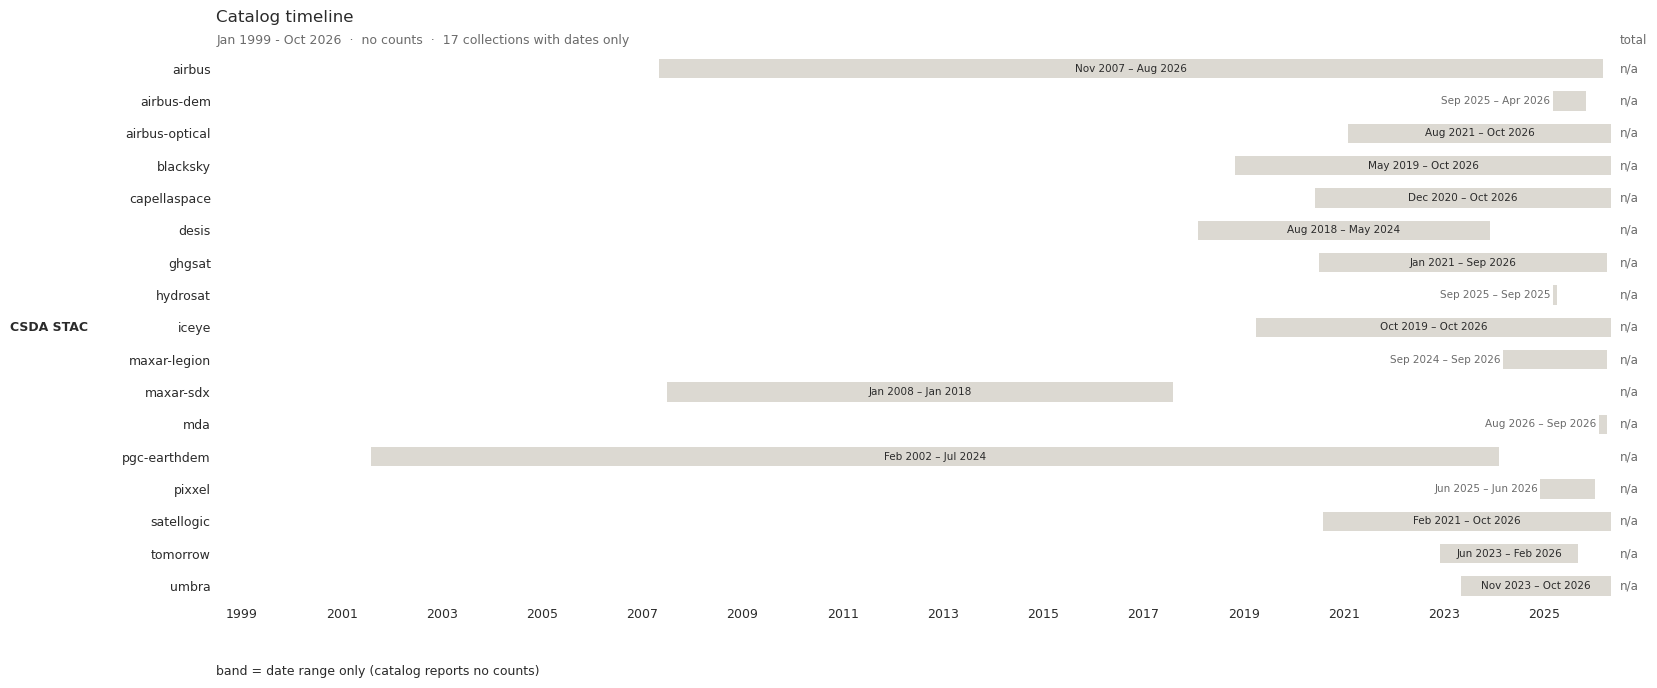

In [34]:
catalog_overview = multistac.overview(PROVIDERS, START, END)
catalog_months = multistac.overview_by_month(PROVIDERS, START, END)
multistac_plots.plot_month_heatmap(catalog_months, spans=catalog_overview, color_by='provider',
                                   start=START[:7], end=END[:7], title='Catalog timeline');
catalog_overview

## 2. Global search

In [35]:
%%time
res = multistac.search(None, START, END, PROVIDERS, cache_dir=CACHE_DIR)
print(res)
res.log[res.log.status == 'failed']

searches: 100%|██████████| 6346/6346 [18:25<00:00,  5.74it/s]   


SearchResult(416869 rows, 416869 unique items, 0 failed tasks)


,provider,collection,site_name,interval,status,count,server_filters,error,seconds


In [36]:
res.summary()

,provider,collection,processing_level,rows,items,sites,in_csda
0,csda,airbus,?,2490,2490,1,2490
1,csda,airbus-dem,DSM,122,122,1,122
2,csda,airbus-dem,DTM,29,29,1,29
3,csda,airbus-dem,PDT,51,51,1,51
4,csda,airbus-optical,ORT,617,617,1,617
5,csda,airbus-optical,ORTHO_HD,11,11,1,11
6,csda,airbus-optical,PRJ,3,3,1,3
7,csda,airbus-optical,SEN,59,59,1,59
8,csda,airbus-optical,SENSOR_HD,12,12,1,12
9,csda,blacksky,?,126,126,1,126


## 3. Where: global acquisition density

In [37]:
res.gdf.head()

,provider,affiliation,constellation,sensor,collection,id,datetime,site_name,cloud_cover,processing_level,product_type,platform,instrument,gsd,off_nadir,incidence_angle,view_azimuth,sun_elevation,sun_azimuth,sat_azimuth,...,blacksky_cloudCoverPercent,blacksky_fractionSaturated,blacksky_processingVersion,blacksky_registrationPoints,blacksky_satelliteElevation,blacksky_numberRegistrationPoints,blacksky_multiImage,blacksky_bisectorAngle,blacksky_asymmetryAngle,blacksky_convergenceAngle,blacksky_coregistrationSuccess,blacksky:gsdGroundPlane,resolution_class,version,hydrosat:scene_id,hydrosat:strip_id,hydrosat:day_night,processing:lineage,sat:platform_international_designator,geometry
0,csda,Vantor,QuickBird,QB02,pgc-earthdem,SETSM_s2s041_QB02_20021222_101001000180F300_10...,2002-02-06 18:43:34+00:00,global,NaN,None,strip,None,"QB02, QB02",2.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-118.46848 34.02319, -118.4632..."
1,csda,Vantor,QuickBird,QB02,pgc-earthdem,SETSM_s2s041_QB02_20021222_101001000180F300_10...,2002-02-06 18:43:35+00:00,global,NaN,None,strip,None,"QB02, QB02",2.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-118.47052 33.86592, -118.4706..."
2,csda,PGC,maxar,None,pgc-earthdem,utm17n_32_04_2_1_2m_v1.1,2002-02-18 00:00:00+00:00,global,NaN,None,mosaic,None,None,2.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-81.51401 28.92784, -80.99897 ..."
3,csda,PGC,maxar,None,pgc-earthdem,utm17n_32_04_1_1_2m_v1.1,2002-02-18 00:00:00+00:00,global,NaN,None,mosaic,None,None,2.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-81.51181 28.47654, -80.99898 ..."
4,csda,Vantor,QuickBird,QB02,pgc-earthdem,SETSM_s2s041_QB02_20020218_10100100001FB300_10...,2002-02-18 16:09:01+00:00,global,NaN,None,strip,None,"QB02, QB02",2.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-81.46745 28.46620, -81.46606 ..."


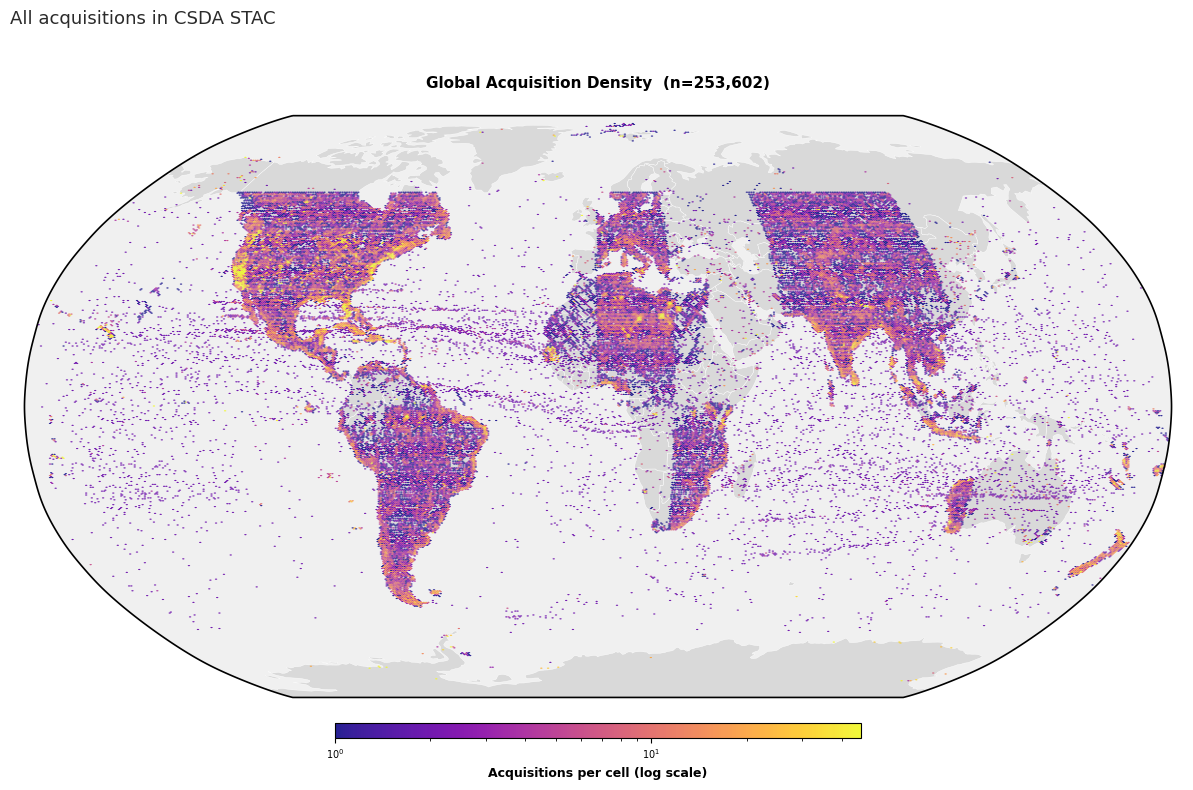

In [31]:
# With your sites overlaid
sites = multistac.load_sites('/home/pmontesa/code/csda_summaries/sites/csda_sites_aoi.geojson',
                             site_name_field='Site Name')
multistac_plots.plot_density_maps(res.gdf, gridsize=500, panel_size=(12,8), 
                                  #sites=sites.rename(columns={'site_name': 'Site Name'}),
                                  title='All acquisitions in CSDA STAC' );

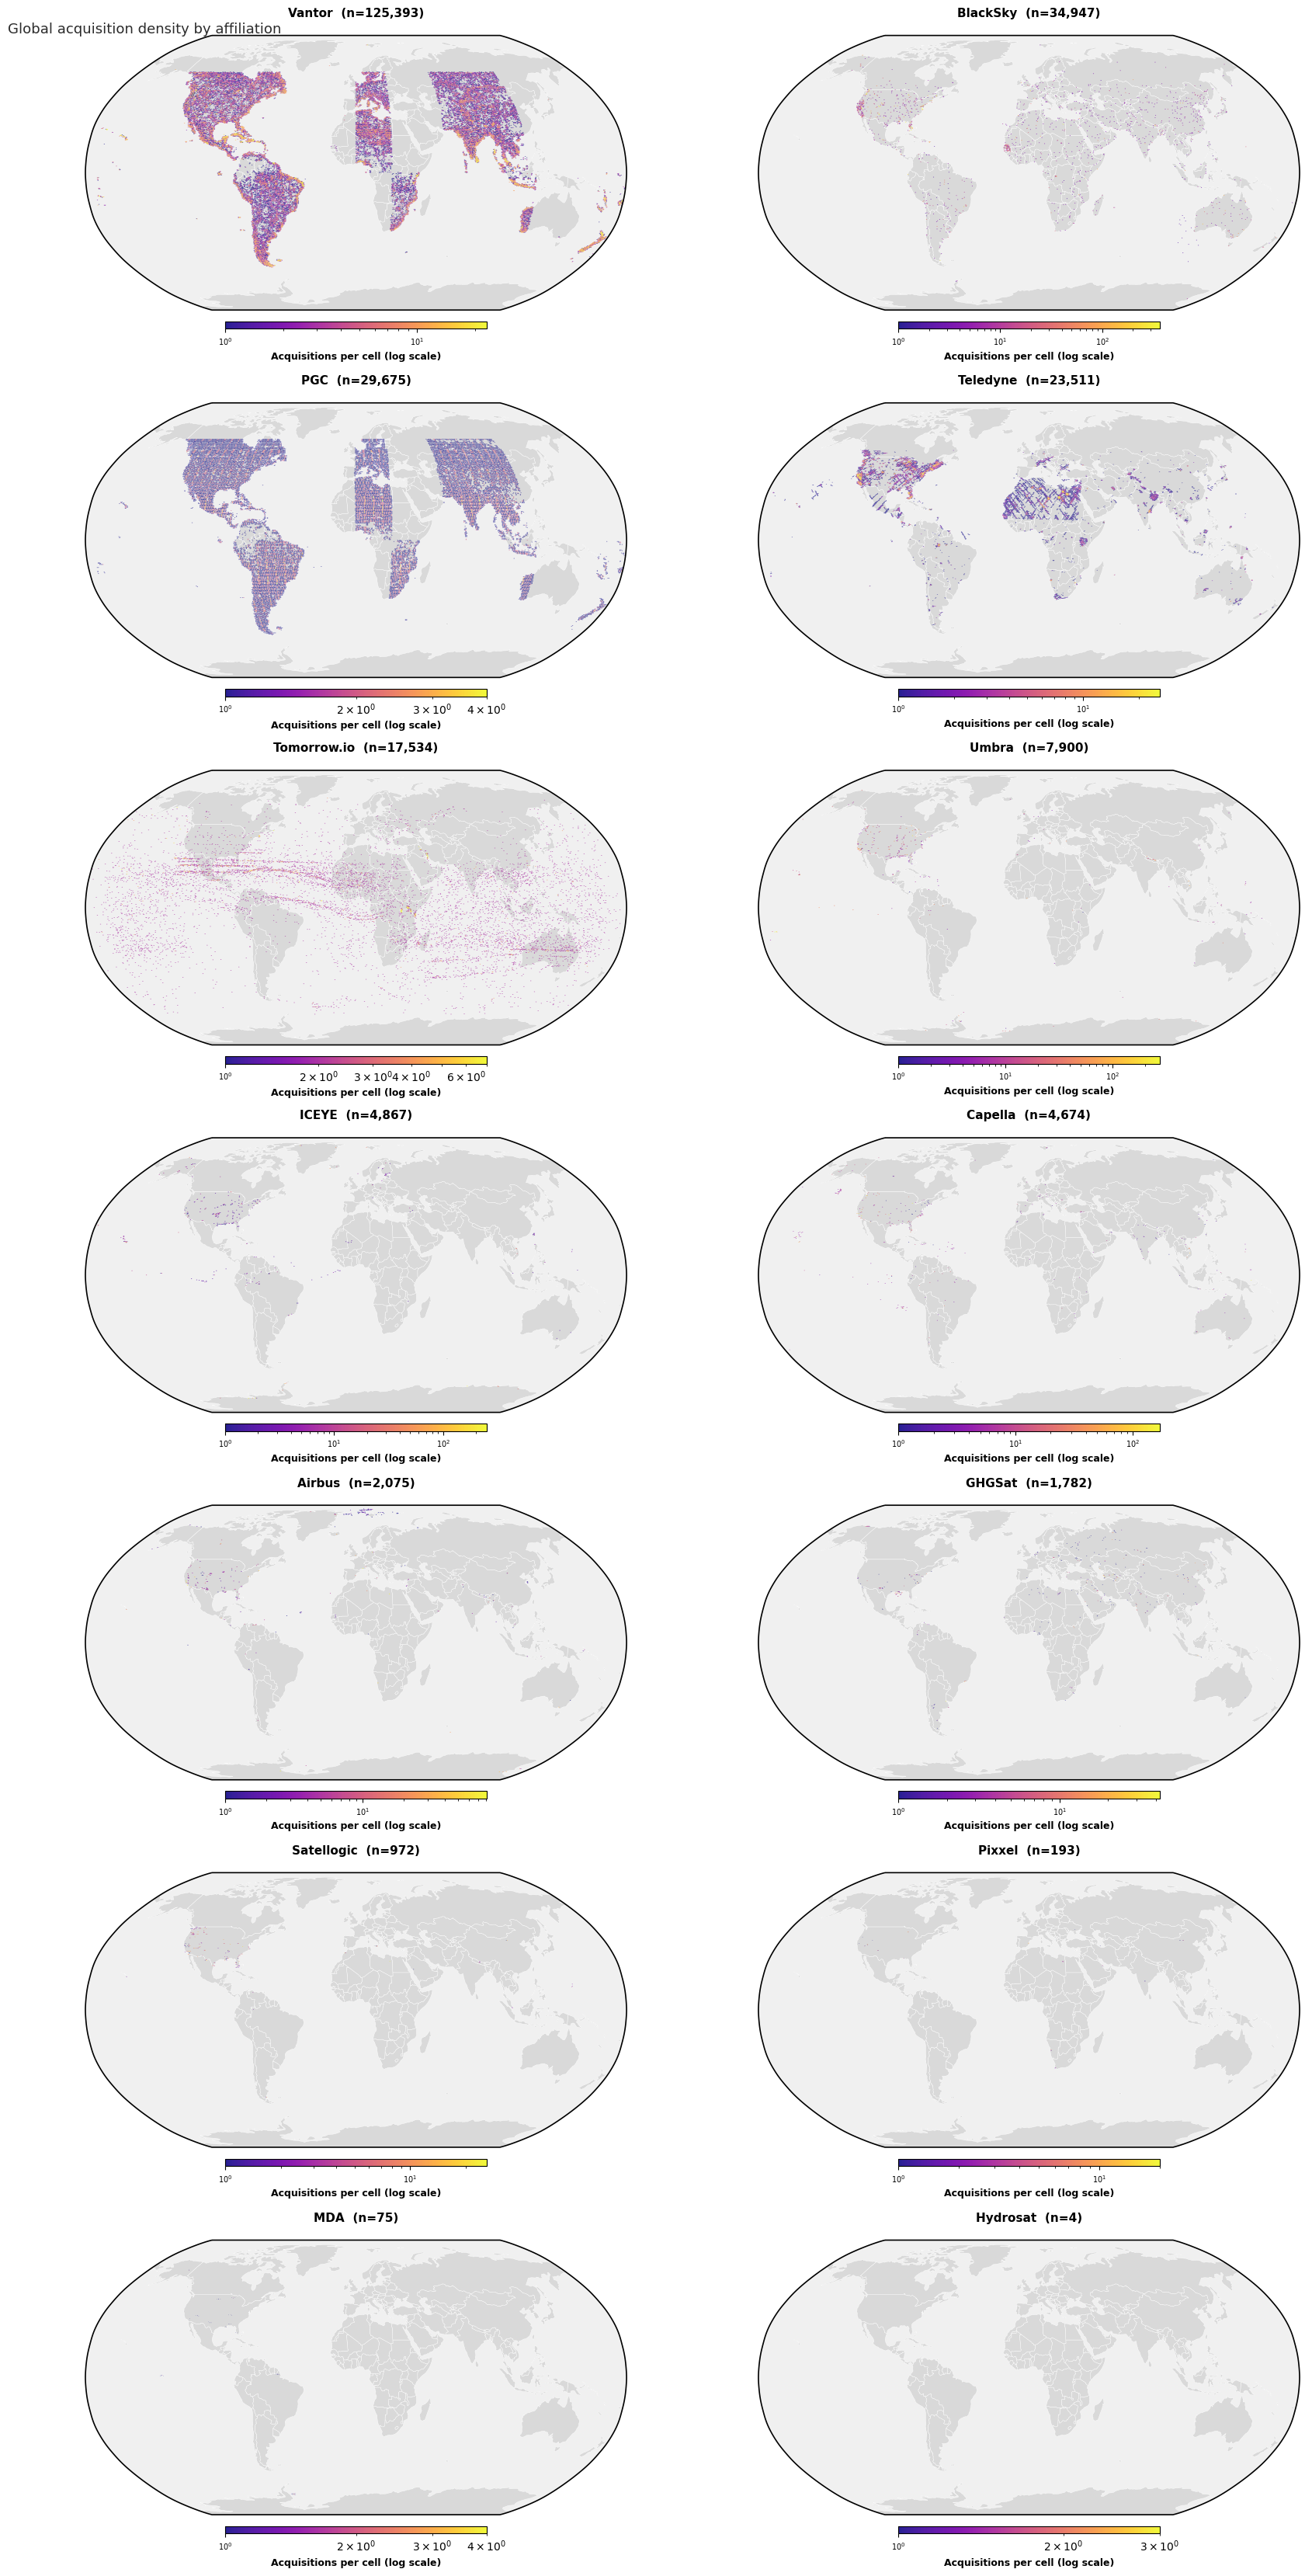

In [23]:
multistac_plots.plot_density_maps(res.gdf, facet_by='affiliation', max_facets=30, gridsize=500,
                                  title='Global acquisition density by affiliation');

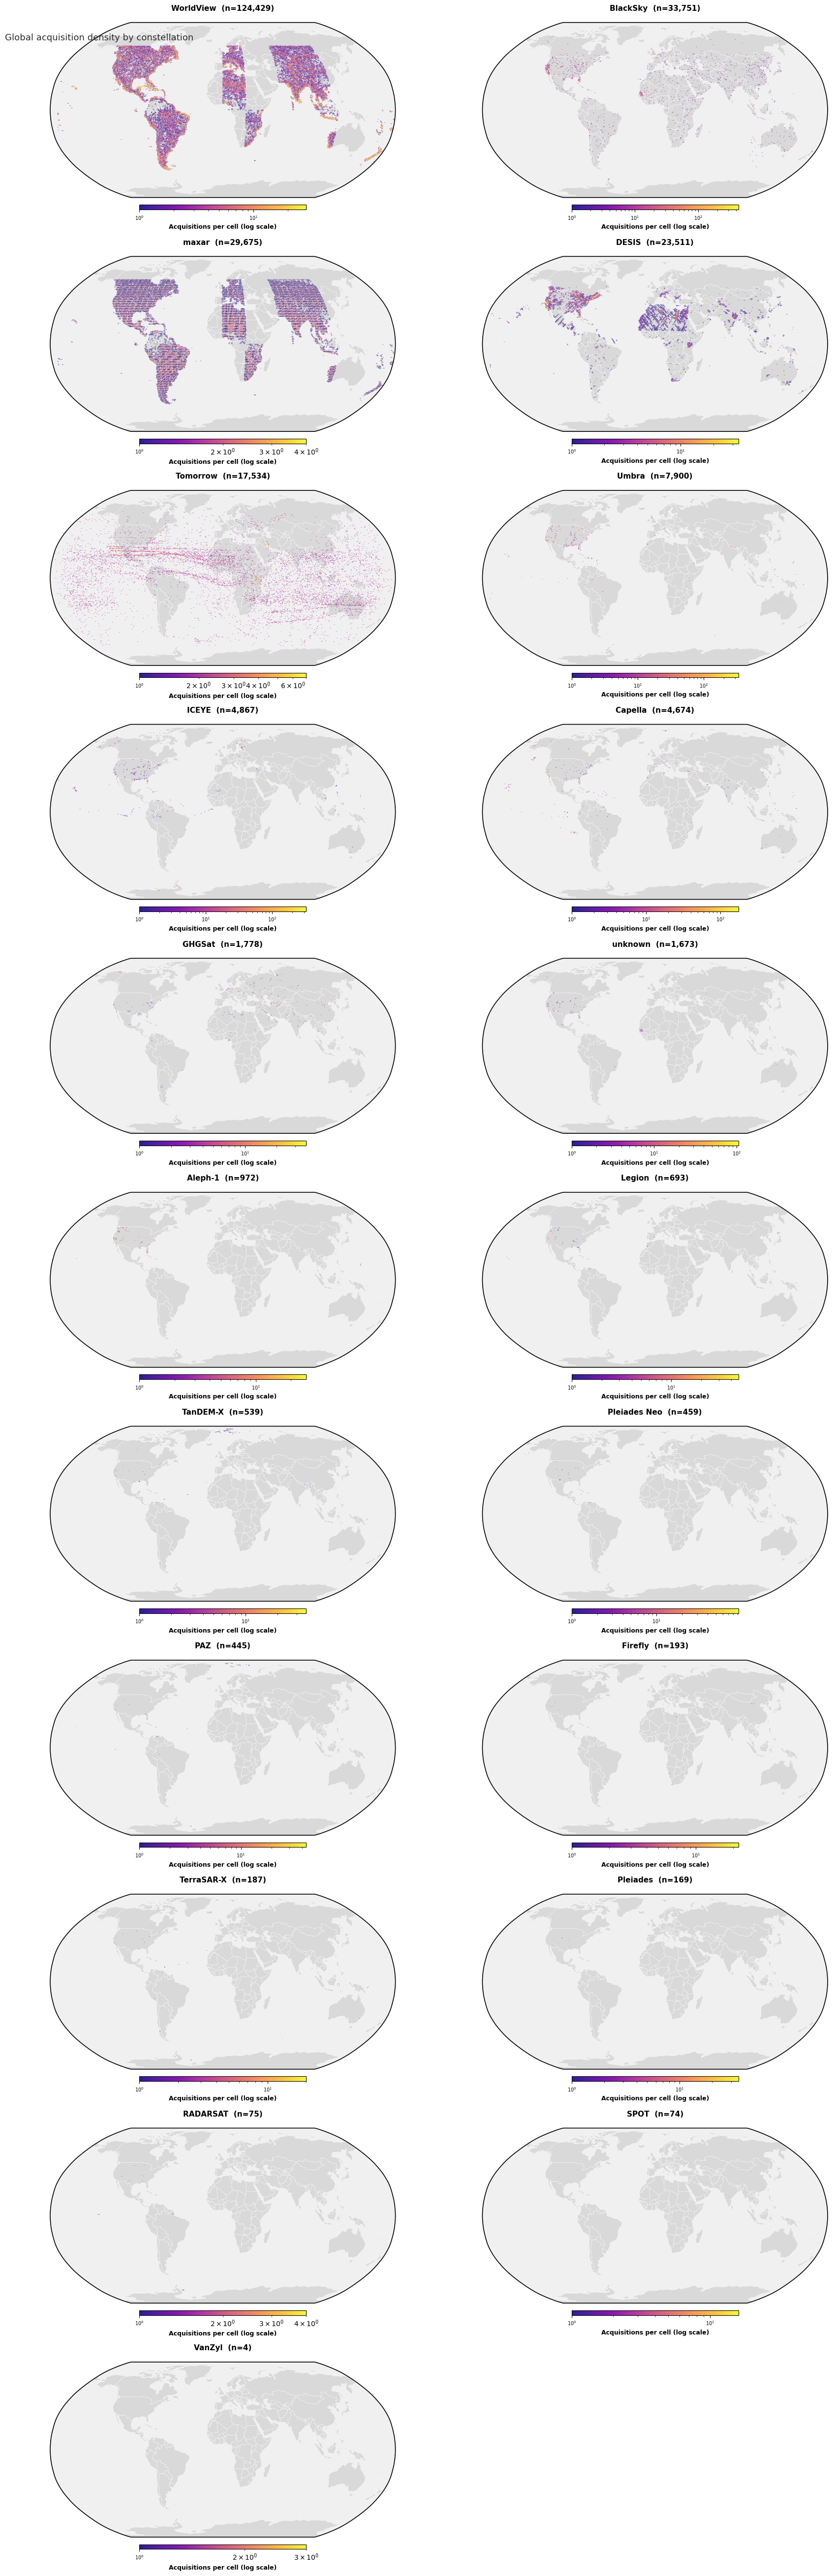

In [24]:
multistac_plots.plot_density_maps(res.gdf, facet_by='constellation', max_facets=30, gridsize=400,
                                  title='Global acquisition density by constellation');

## 4. When

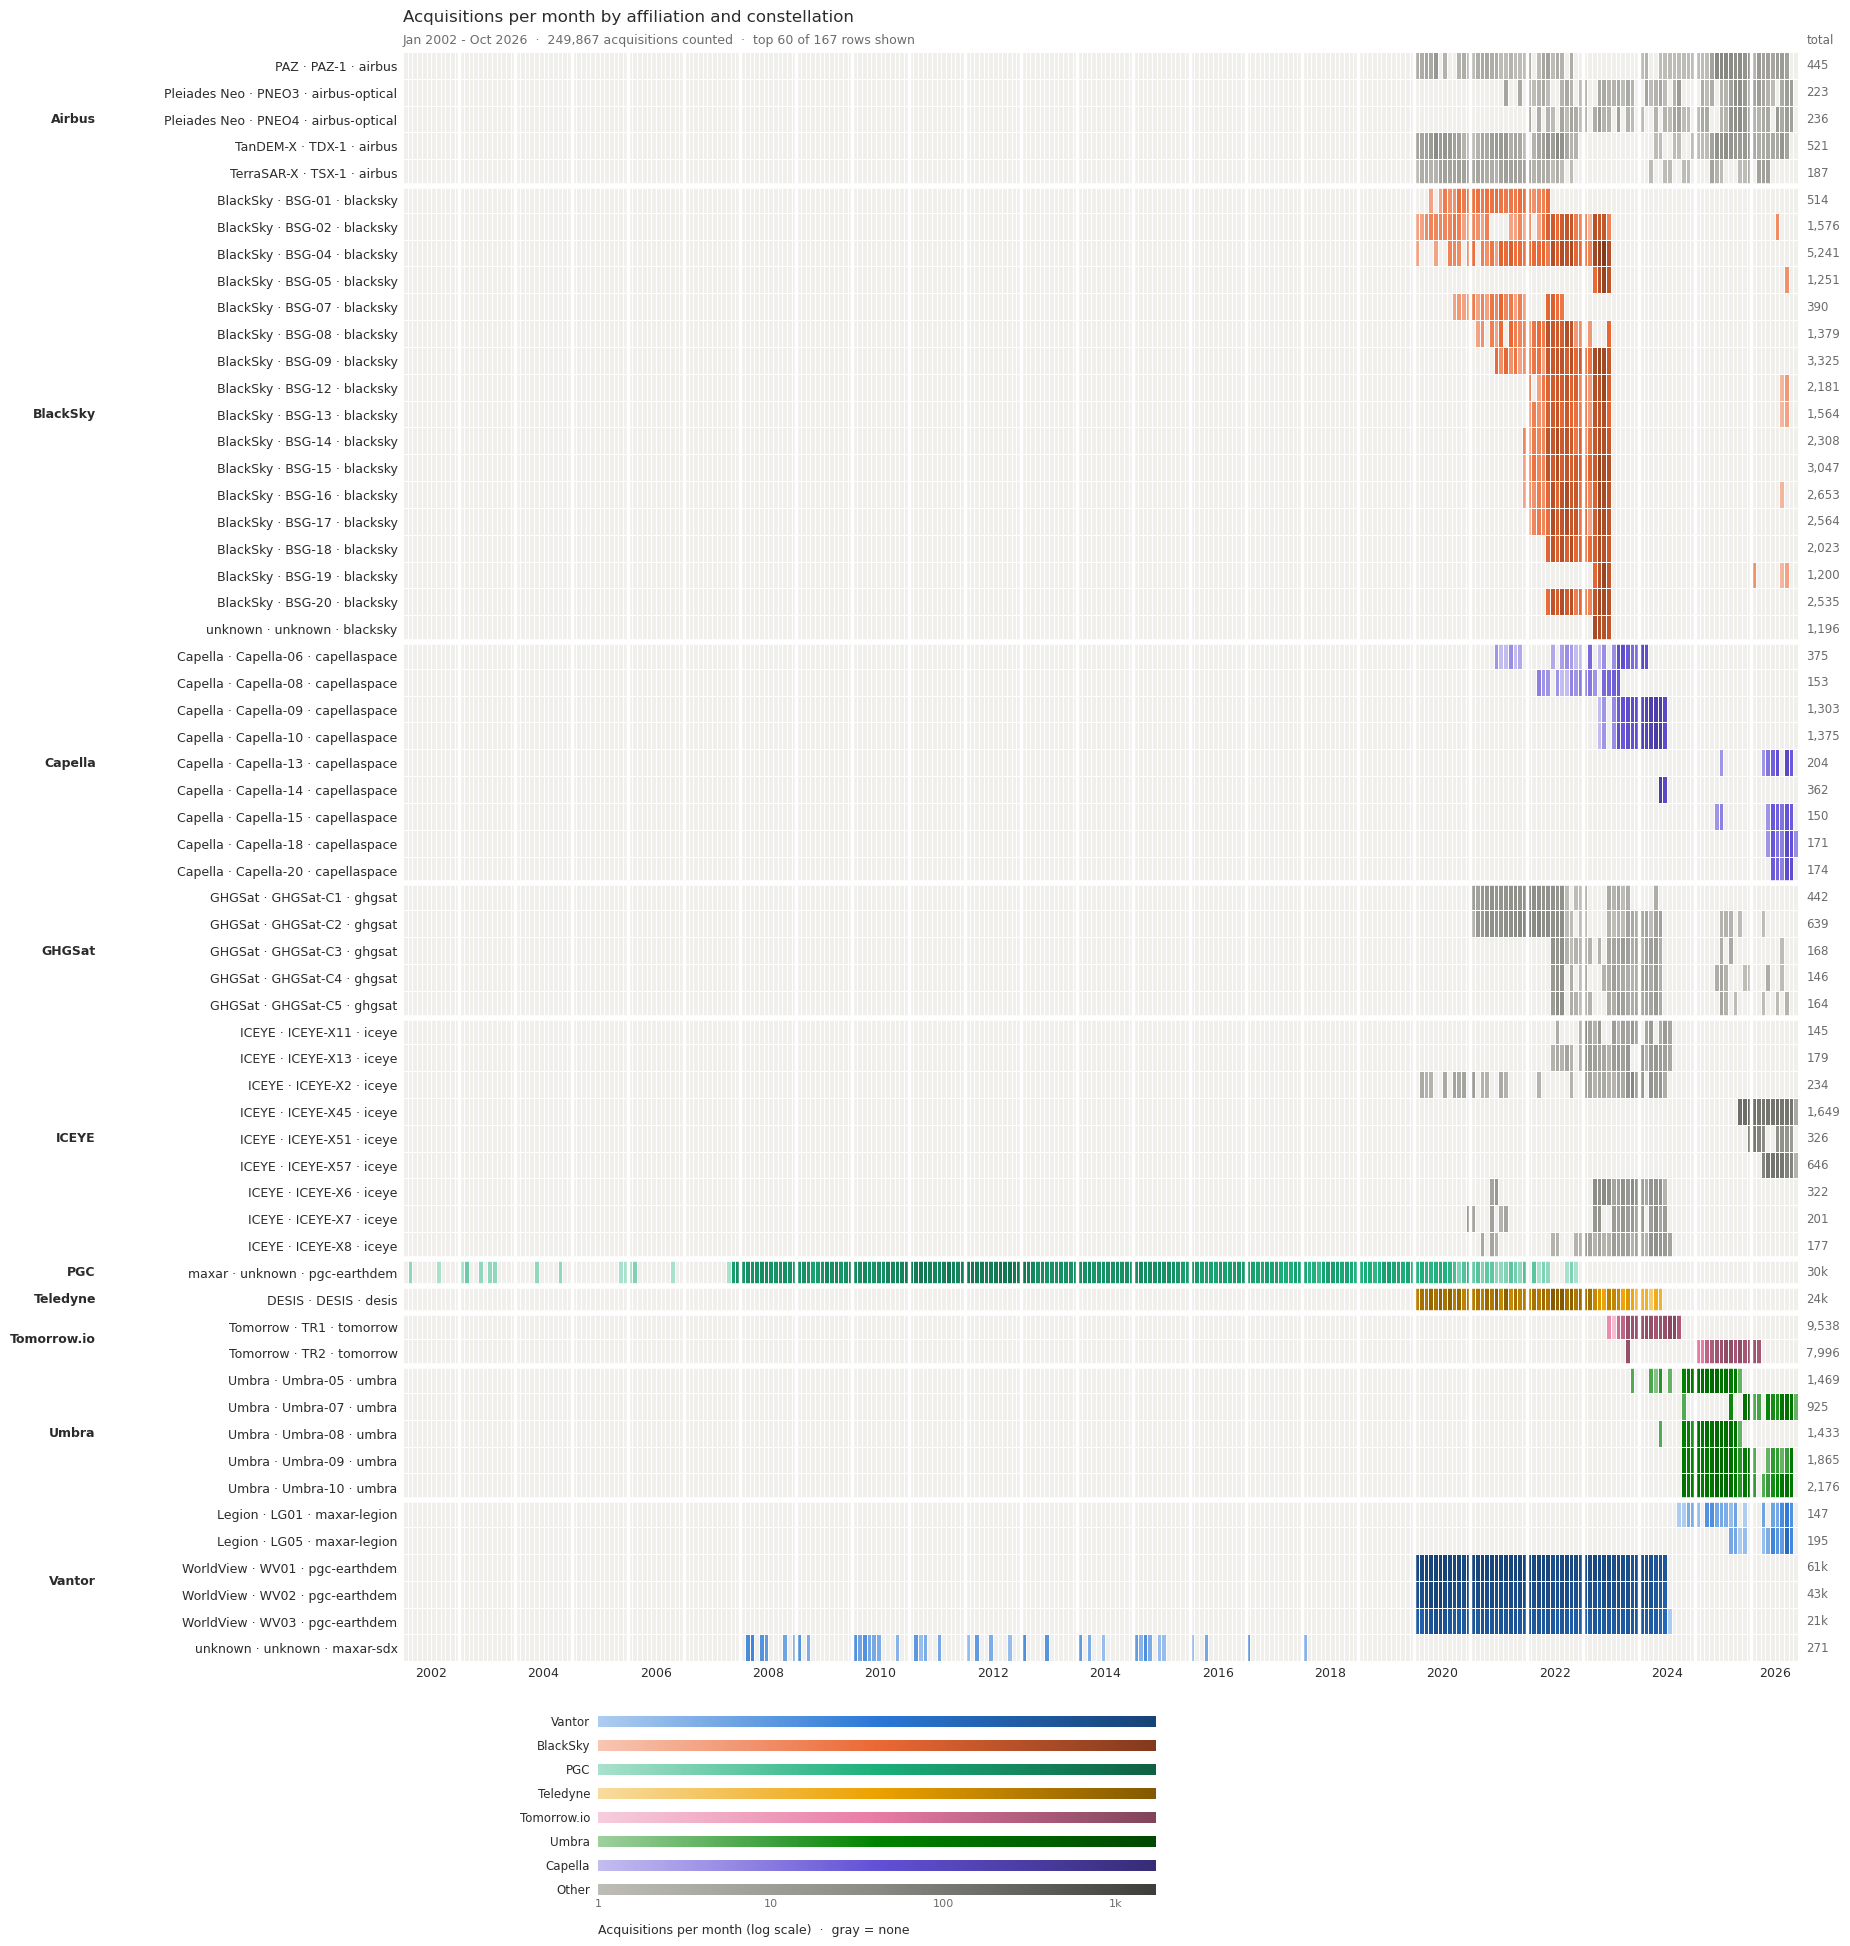

In [27]:
multistac_plots.plot_month_heatmap(res.by_month(['affiliation',	'constellation', 'sensor', 'collection']), color_by='affiliation',
                                   title='Acquisitions per month by affiliation and constellation');

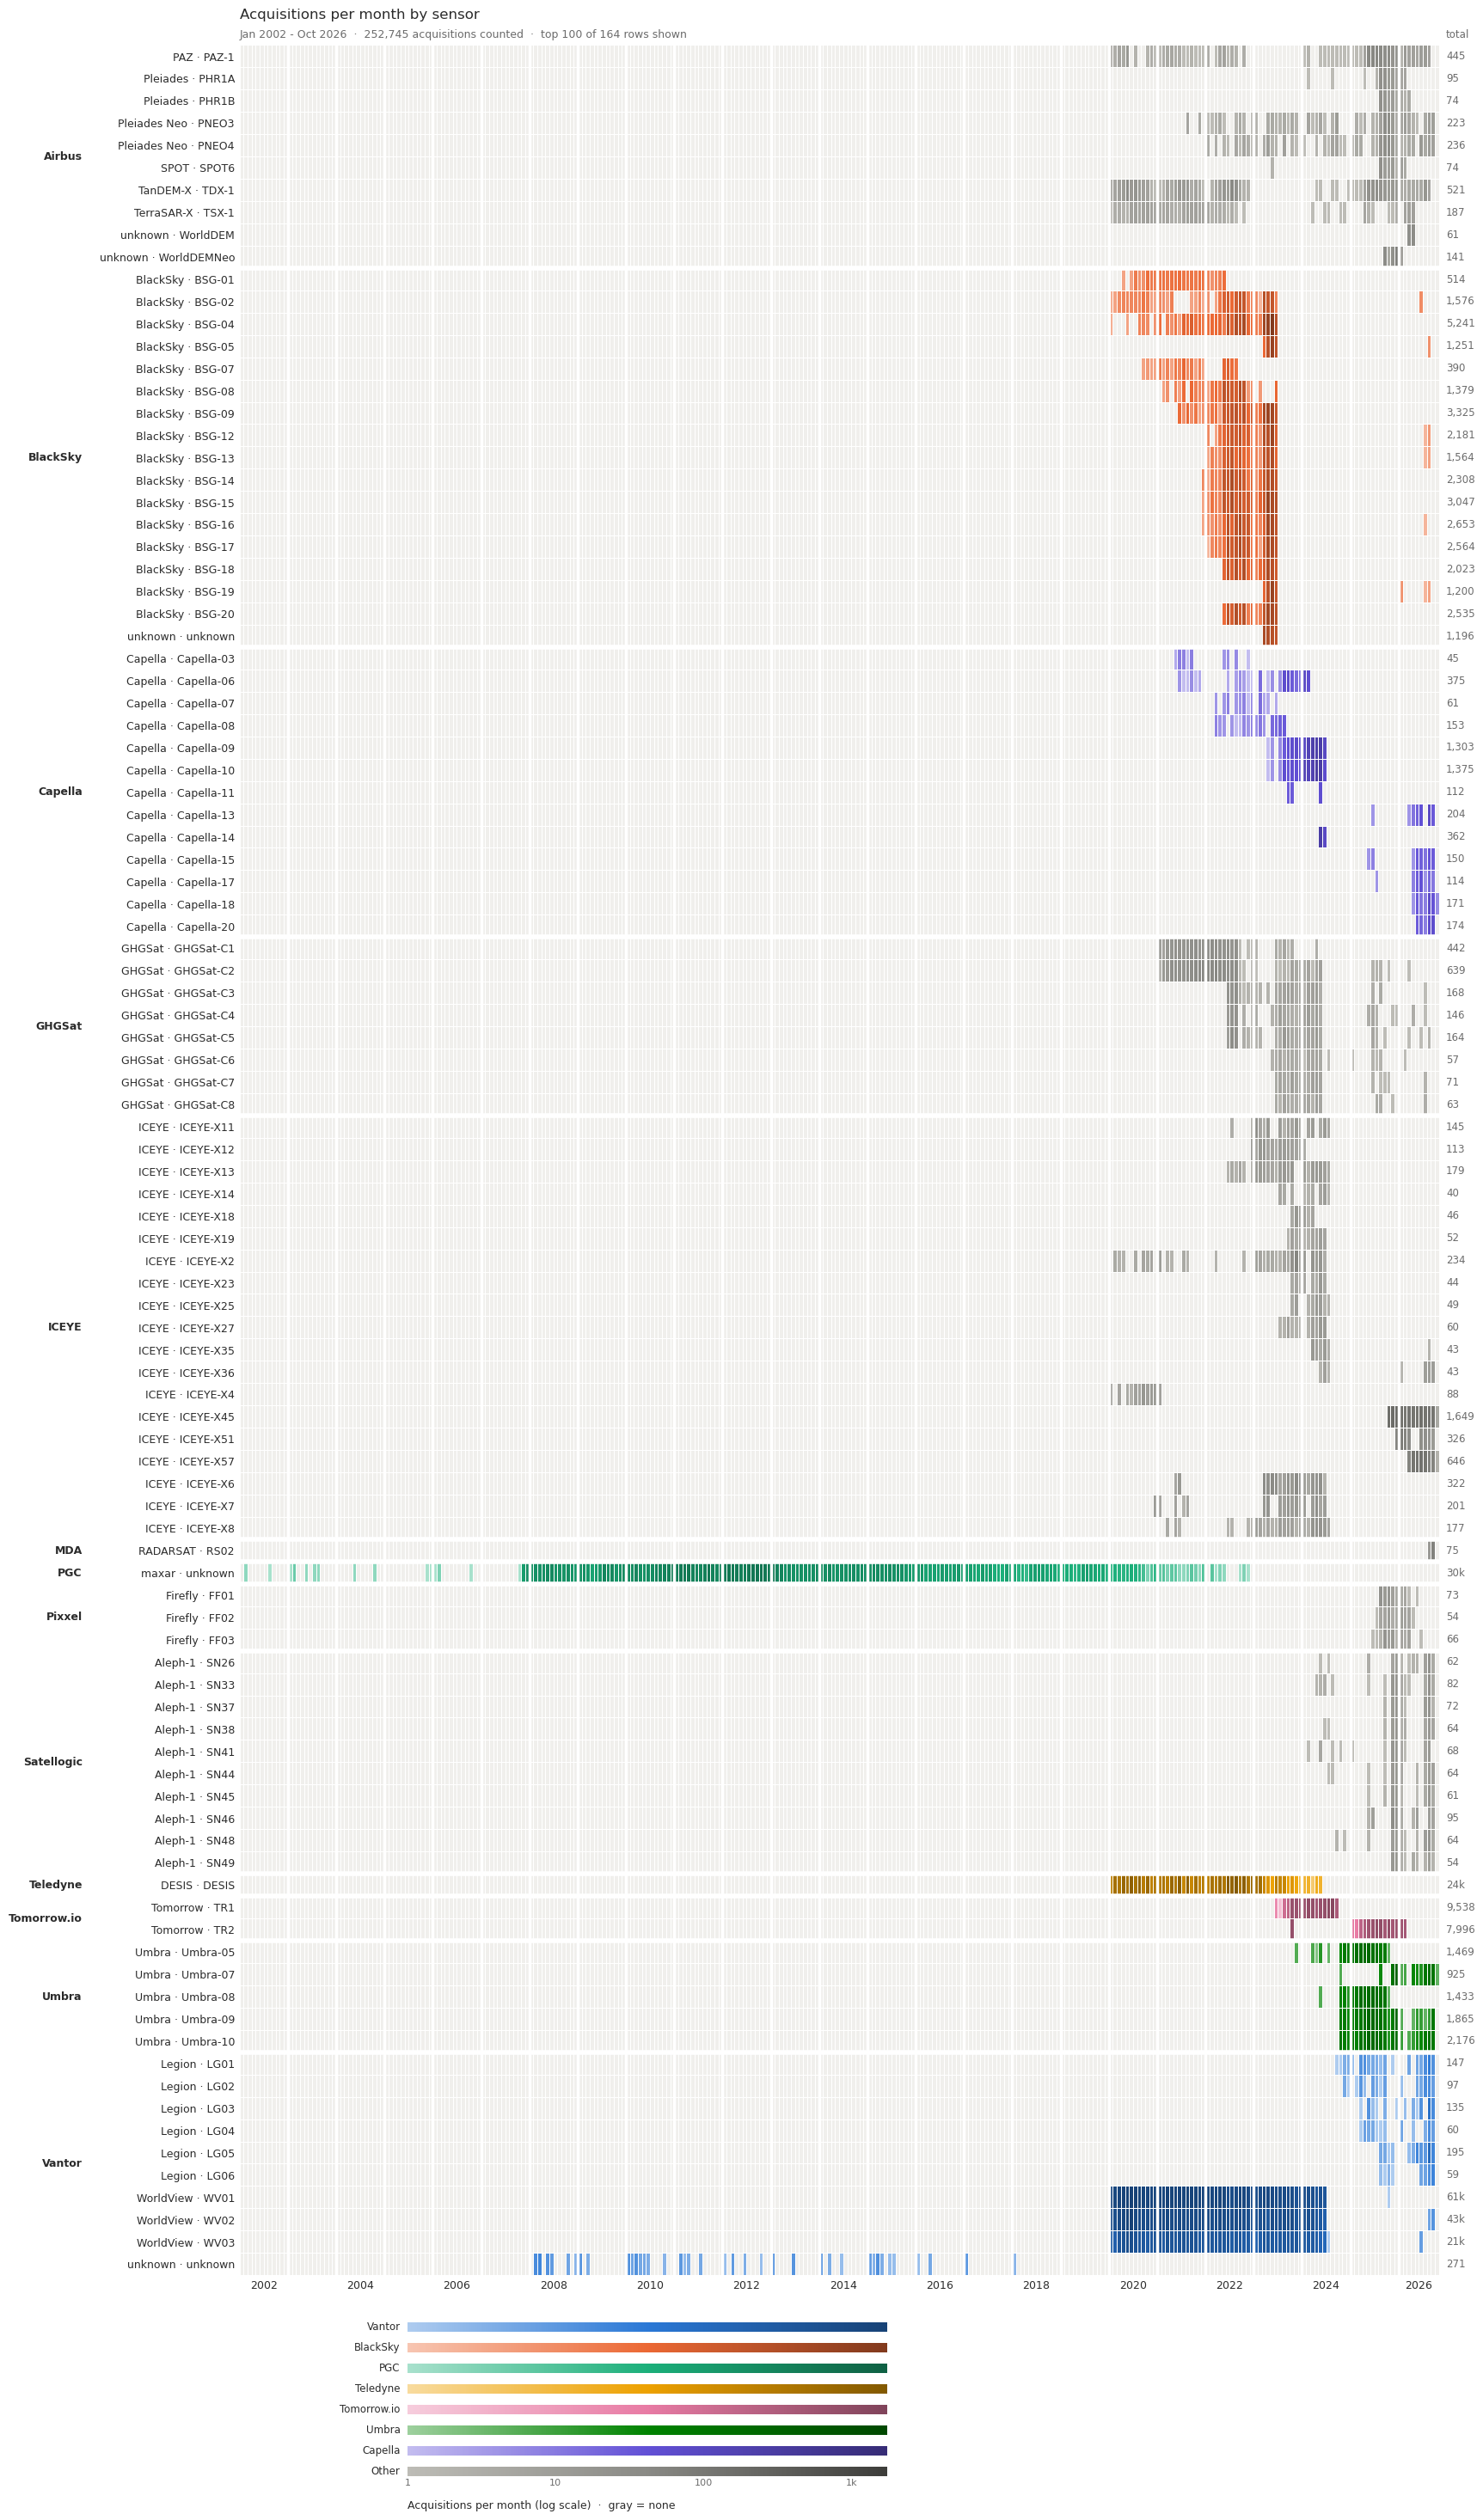

In [20]:
by_sensor = multistac.month_table(res.gdf[res.gdf.constellation != 'PlanetScope'],
                                  ['affiliation', 'constellation', 'sensor'])
multistac_plots.plot_month_heatmap(by_sensor, color_by='affiliation', max_rows=100,
                                   title='Acquisitions per month by sensor');

## 5. Inherent variation

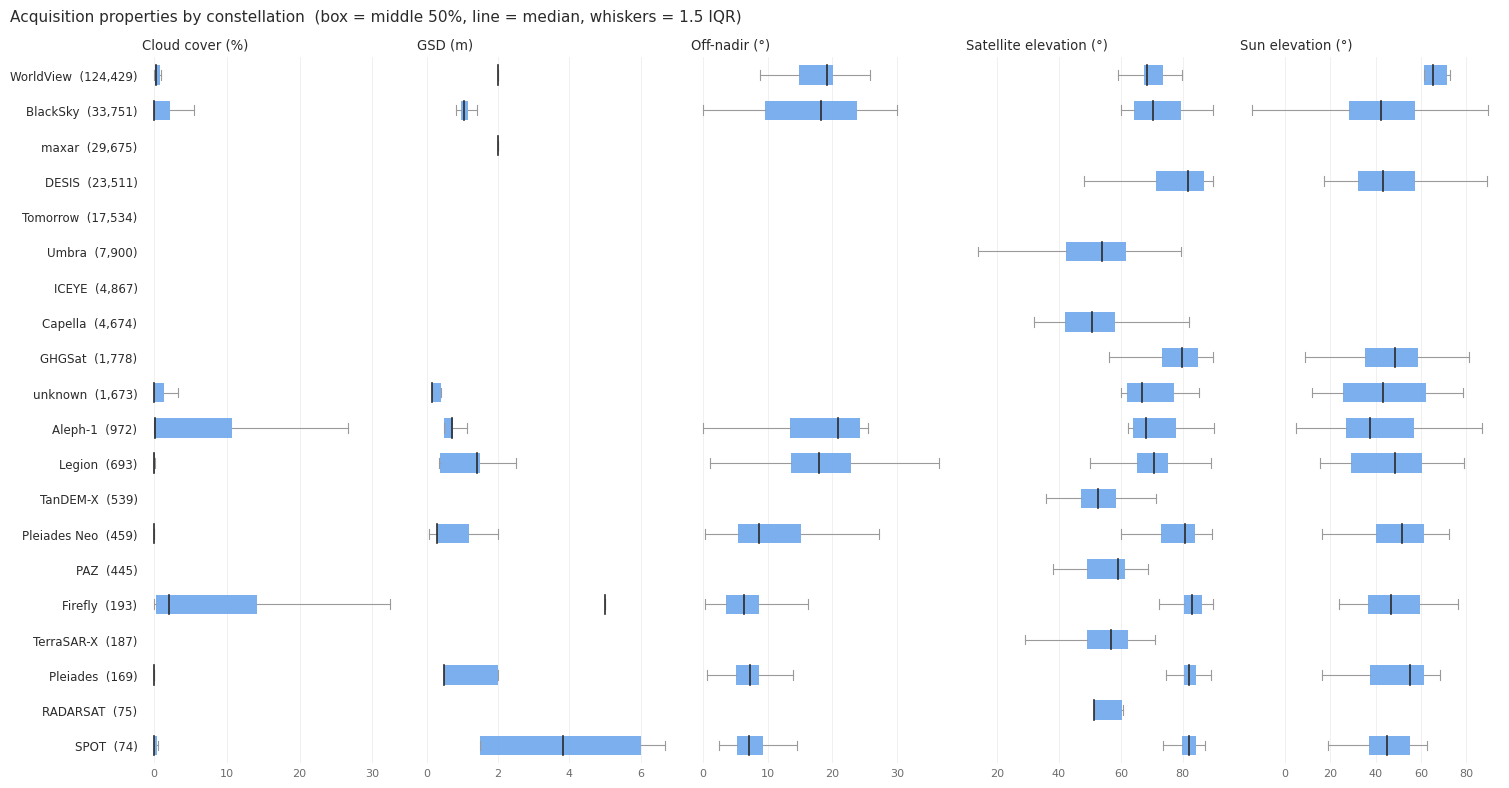

In [12]:
multistac_plots.plot_distributions(res.gdf, by='constellation');

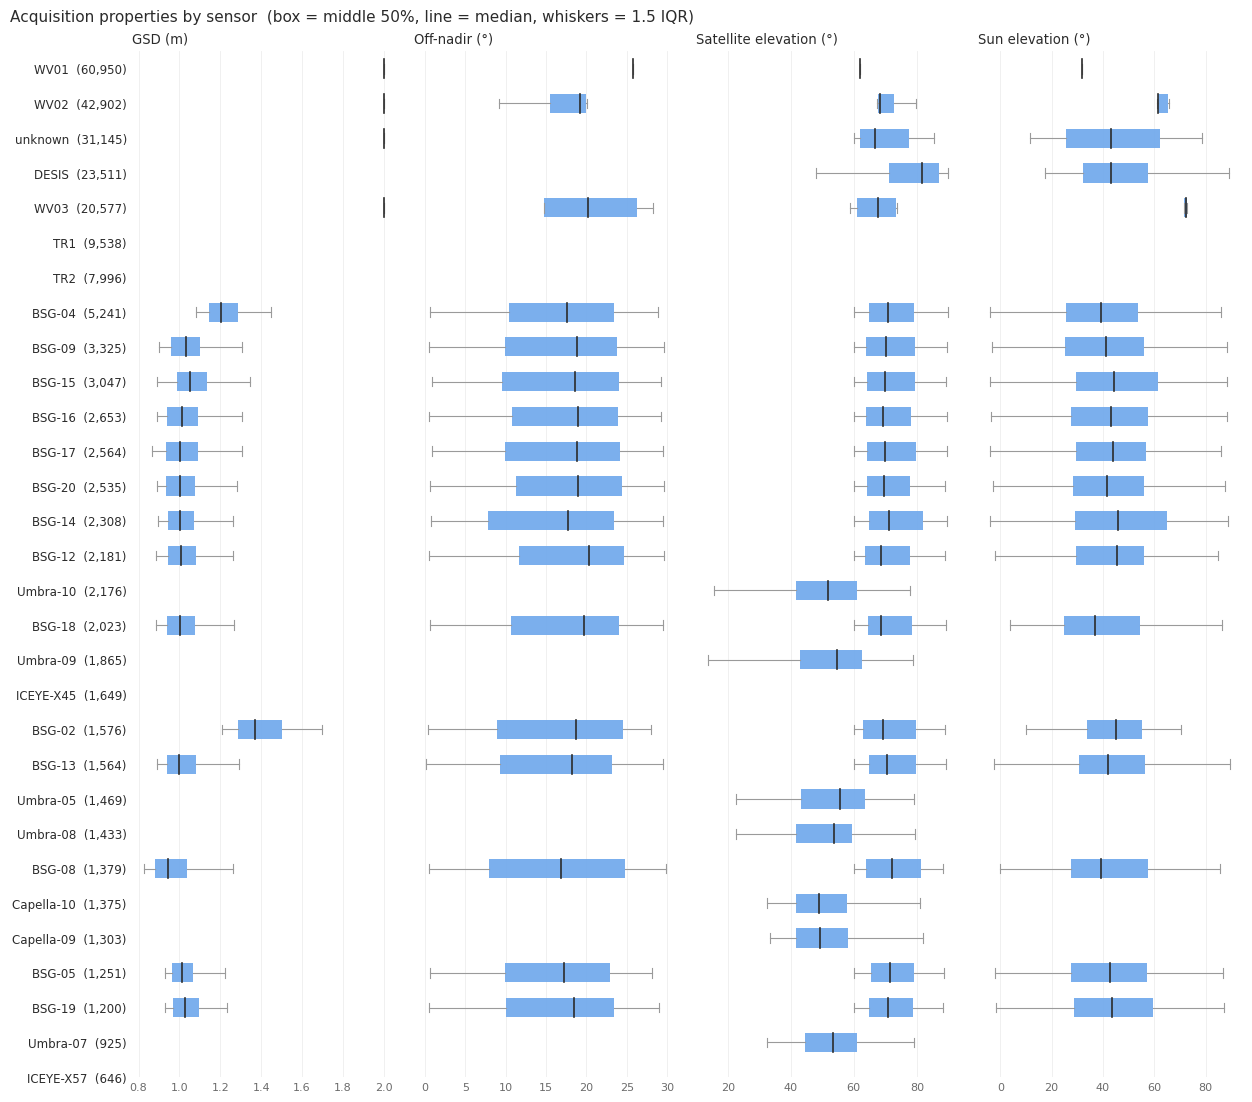

In [13]:
multistac_plots.plot_distributions(res.gdf, by='sensor', max_groups=30,
                                   columns=['gsd', 'off_nadir', 'sat_elevation', 'sun_elevation']);

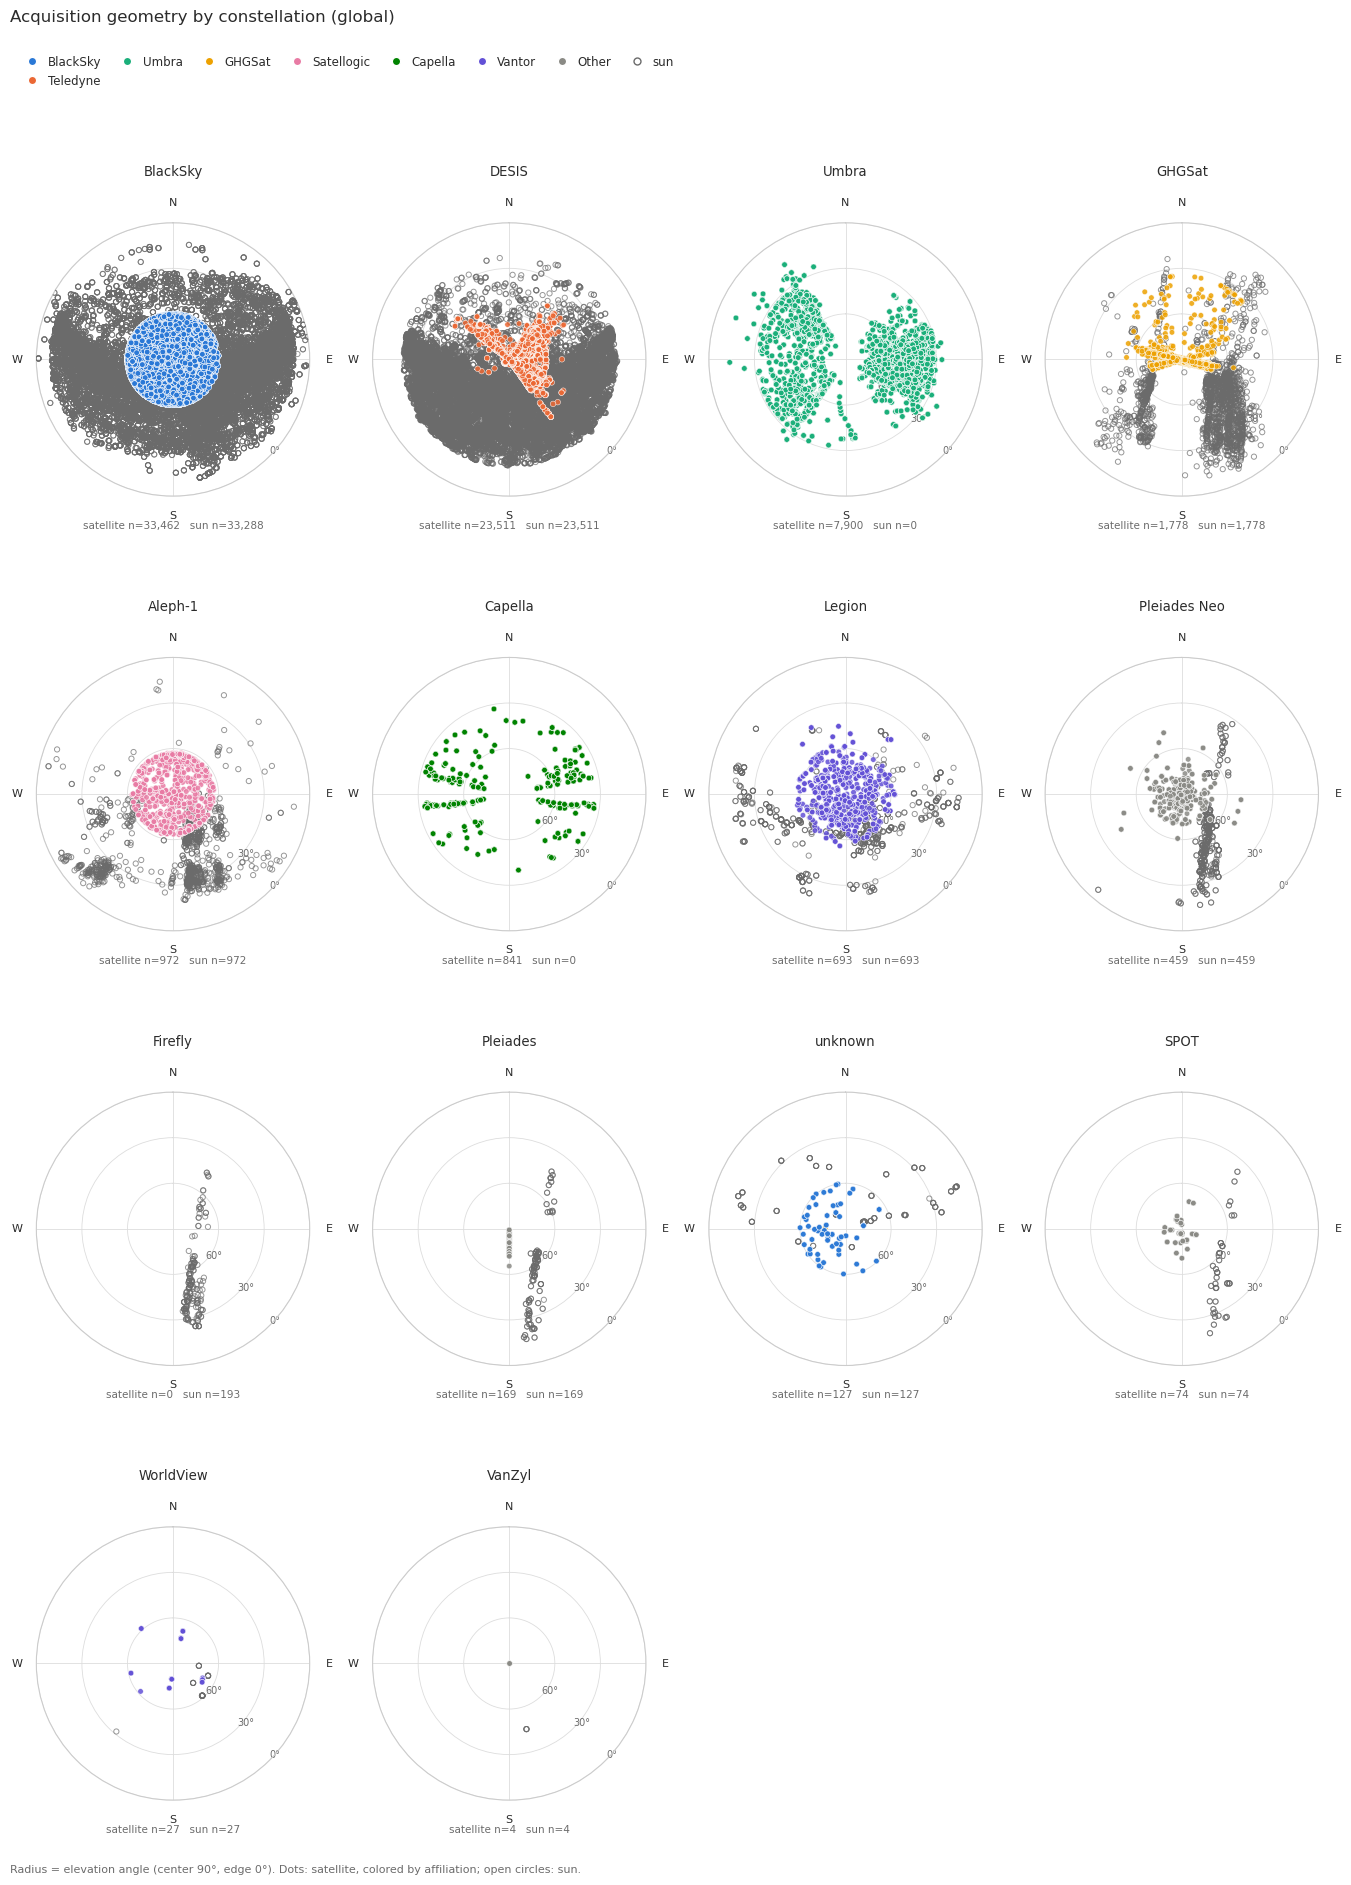

In [19]:
multistac_plots.plot_skyplot(res.gdf, facet_by='constellation', color_by='affiliation', max_facets=30,
                             title='Acquisition geometry by constellation (global)');

In [15]:
# Processing levels and product types per collection
res.gdf.groupby(['provider', 'collection', 'processing_level', 'product_type'], dropna=False).size().rename('n').reset_index()

,provider,collection,processing_level,product_type,n
0,csda,airbus,NaN,NaN,1171
1,csda,airbus-dem,DSM,DSM,122
2,csda,airbus-dem,DTM,DTM,29
3,csda,airbus-dem,PDT,PDT,51
4,csda,airbus-optical,ORT,MS,143
...,...,...,...,...,...
57,csda,satellogic,L1D,l1d,66
58,csda,satellogic,L1D_SR,L1D_SR,642
59,csda,tomorrow,NaN,L1C-GEOPROF,8767
60,csda,tomorrow,NaN,L2A-PRECIP,8767


## Save

In [ ]:
# res.save(f'{OUT_DIR}/global_{START[:4]}_{END[:4]}')